# 02 · Análisis descriptivo y contexto nacional

**Objetivo:** describir la evolución del IRCA en el Cauca, identificar los municipios con mayor riesgo, medir la brecha urbano-rural y comparar al departamento con el resto del país en 2025.

La lógica vive en `src/analysis.py`; este notebook la ejecuta paso a paso y muestra las tablas y figuras.

In [1]:
import os
import sys
from pathlib import Path

BASE = Path.cwd()
if BASE.name == "notebooks":
    BASE = BASE.parent
    os.chdir(BASE)
sys.path.insert(0, str(BASE))

import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
print("Directorio de trabajo:", Path.cwd())

Directorio de trabajo: C:\Users\chris\Desktop\electiva-profesional-ii-trabajo-final


## 1. Carga de las tablas limpias

In [2]:
from src.analysis import cargar

cauca, dep, nac_mun, nac_dep = cargar()
print("Cauca municipal:", cauca.shape)
print("Cauca departamento:", dep.shape)
print("Nacional municipal 2025:", nac_mun.shape)
print("Nacional departamental 2025:", nac_dep.shape)

Cauca municipal: (736, 16)
Cauca departamento: (19, 16)
Nacional municipal 2025: (1019, 16)
Nacional departamental 2025: (33, 16)


## 2. Evolución departamental

El IRCA departamental pasó de 30,7 en 2007 a 3,3 en 2024 y subió a 7,3 en 2025. La serie urbana y rural permite ver que la rural es más volátil y tiene más años sin dato.

In [3]:
from src.analysis import resumen_anual

resumen = resumen_anual(cauca, dep)
resumen.tail(5)[
    [
        "anio",
        "municipios_con_dato",
        "irca_departamental",
        "nivel_riesgo_departamental",
        "irca_promedio",
        "irca_mediana",
        "pct_riesgo_medio_alto",
        "pct_rural_sin_dato",
    ]
]

,anio,municipios_con_dato,irca_departamental,nivel_riesgo_departamental,irca_promedio,irca_mediana,pct_riesgo_medio_alto,pct_rural_sin_dato
14,2021,36,9.9,Riesgo bajo,11.41,6.65,19.4,55.6
15,2022,34,7.2,Riesgo bajo,7.81,5.35,8.8,52.9
16,2023,33,3.9,Sin riesgo,5.51,0.90,18.2,54.5
17,2024,33,3.3,Sin riesgo,3.80,1.30,9.1,57.6
18,2025,38,7.3,Riesgo bajo,7.66,6.10,10.6,78.9


In [4]:
dep[dep["anio"].isin([2007, 2010, 2015, 2020, 2023, 2024, 2025])][
    ["anio", "irca", "nivel_riesgo", "irca_urbano", "irca_rural"]
]

,anio,irca,nivel_riesgo,irca_urbano,irca_rural
0,2007,30.7,Riesgo medio,31.0,24.3
3,2010,23.1,Riesgo medio,22.4,44.3
8,2015,14.7,Riesgo medio,14.2,40.6
13,2020,7.6,Riesgo bajo,7.3,9.6
16,2023,3.9,Sin riesgo,4.0,3.6
17,2024,3.3,Sin riesgo,2.1,6.6
18,2025,7.3,Riesgo bajo,6.6,9.9


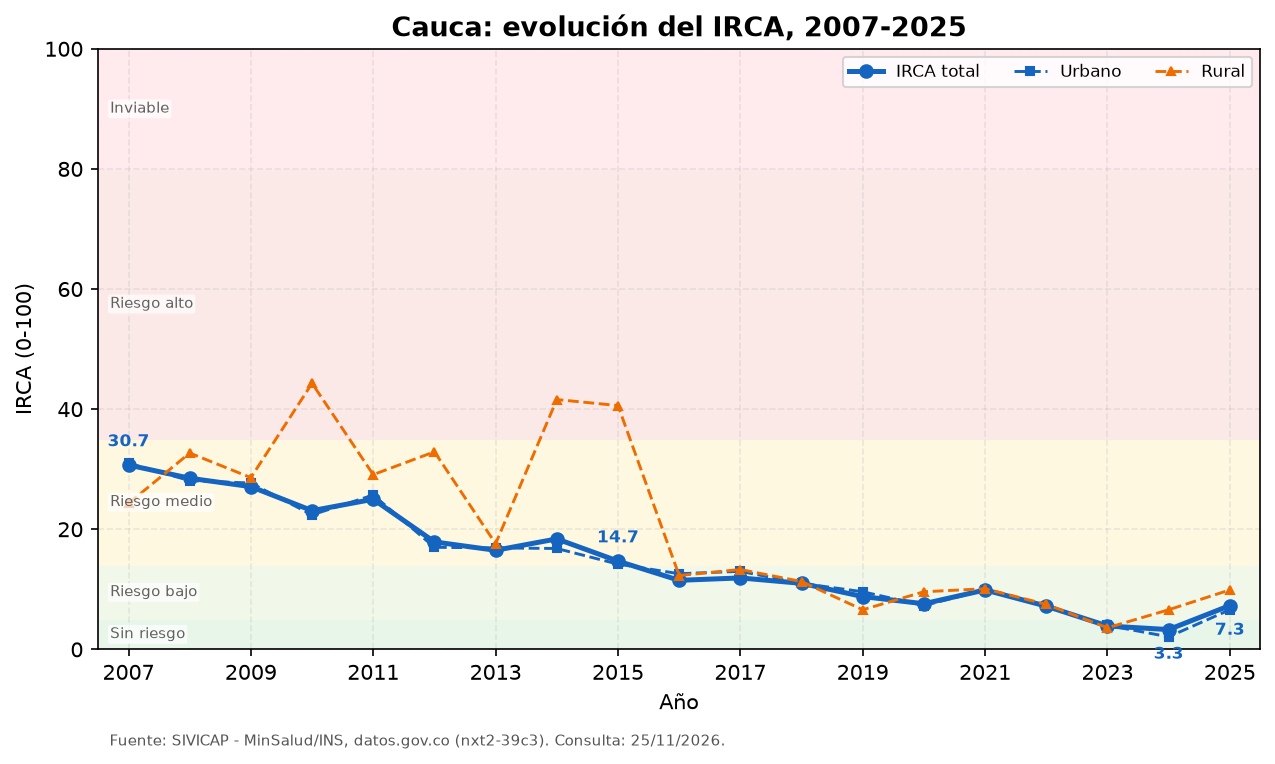

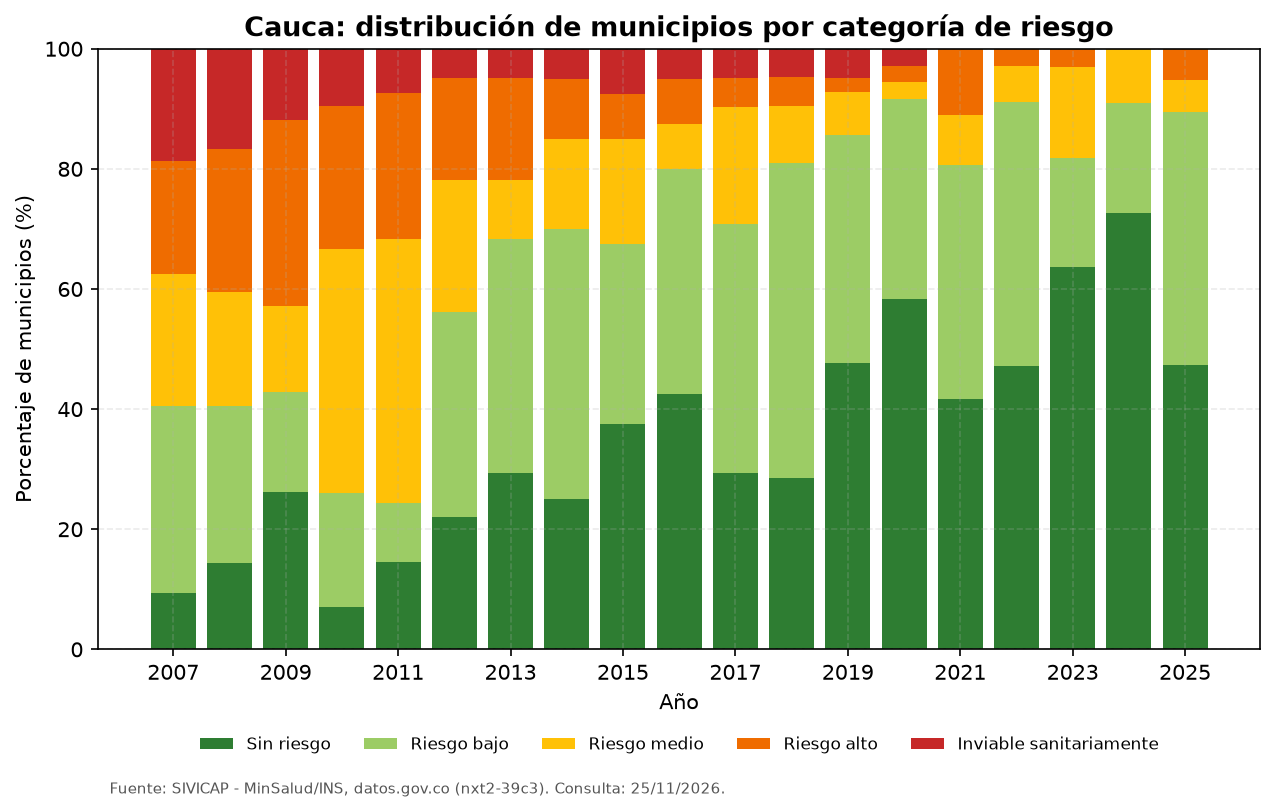

In [5]:
from IPython.display import Image, display
from src.analysis import fig_evolucion, fig_categorias

fig_evolucion(dep)
fig_categorias(resumen)
display(Image(filename="figures/fig_01_evolucion_cauca.png", width=900))
display(Image(filename="figures/fig_02_categorias_riesgo.png", width=900))

## 3. Ranking municipal 2025

En 2025 hay 38 municipios con dato: 18 sin riesgo, 16 en riesgo bajo, 2 en riesgo medio y 2 en riesgo alto. Cuatro municipios concentran el riesgo medio/alto.

In [6]:
from src.analysis import persistencia, ranking_2025, fig_ranking

persist = persistencia(cauca)
ranking = ranking_2025(cauca, nac_mun, persist)
ranking.head(10)[
    [
        "municipio",
        "irca",
        "nivel_riesgo",
        "irca_urbano",
        "irca_rural",
        "brecha_rural_urbano",
        "puesto_departamental",
        "puesto_nacional",
        "percentil_nacional",
    ]
]

,municipio,irca,nivel_riesgo,irca_urbano,irca_rural,brecha_rural_urbano,puesto_departamental,puesto_nacional,percentil_nacional
33,Timbiquí,37.0,Riesgo alto,37.0,NaN,NaN,1,59,94.3
5,Caldono,36.6,Riesgo alto,18.8,67.8,49.0,2,60,94.2
10,Guapi,32.0,Riesgo medio,32.0,NaN,NaN,3,72,93.0
37,Villa Rica,19.1,Riesgo medio,19.1,NaN,NaN,4,168,83.6
18,Padilla,12.6,Riesgo bajo,12.6,NaN,NaN,5,276,73.0
12,Jambaló,12.5,Riesgo bajo,12.5,NaN,NaN,6,280,72.6
15,Mercaderes,12.4,Riesgo bajo,12.4,NaN,NaN,7,283,72.3
32,Suárez,11.5,Riesgo bajo,11.5,NaN,NaN,8,303,70.4
20,Piamonte,11.4,Riesgo bajo,11.4,NaN,NaN,9,306,70.1
4,Cajibío,11.1,Riesgo bajo,18.8,5.1,-13.7,10,316,69.1


In [7]:
print("Distribución 2025:")
print(ranking["nivel_riesgo"].value_counts().to_string())
print("\nMunicipios sin dato en 2025:")
print(sorted(set(cauca["municipio"]) - set(ranking["municipio"])))

Distribución 2025:
nivel_riesgo
Sin riesgo      18
Riesgo bajo     16
Riesgo alto      2
Riesgo medio     2

Municipios sin dato en 2025:
['Balboa', 'Florencia', 'López de Micay', 'Popayán']


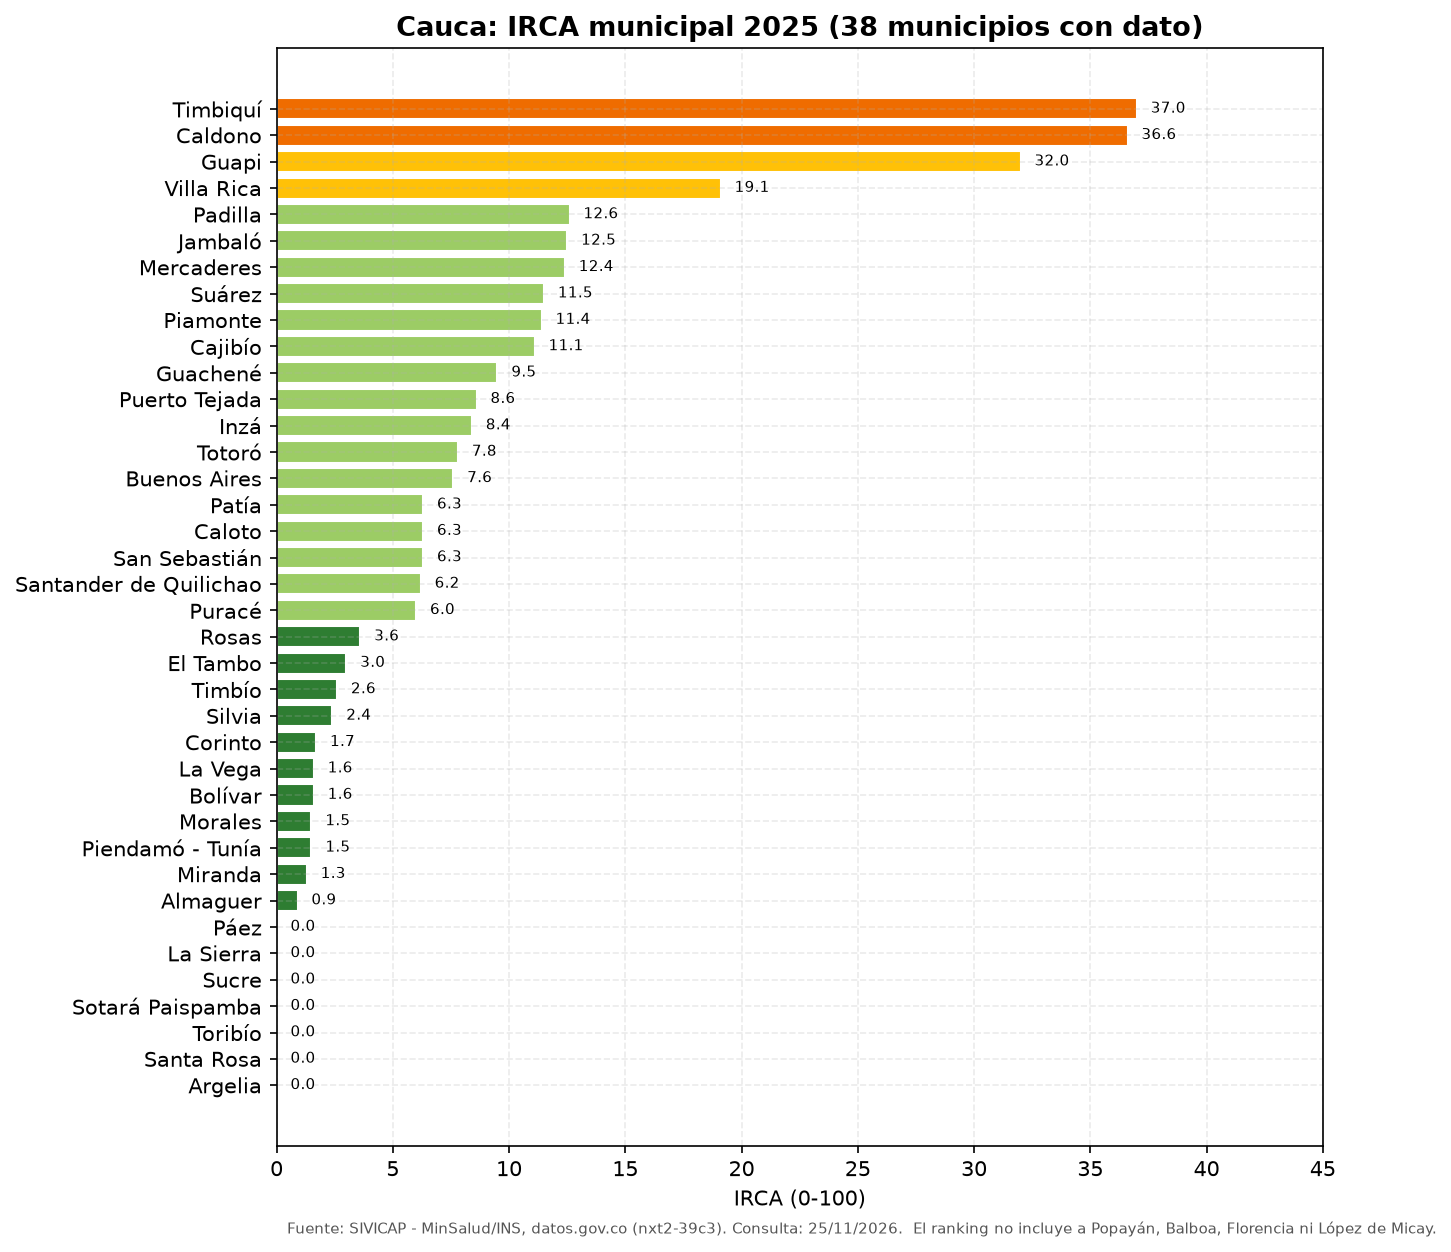

In [8]:
fig_ranking(ranking)
display(Image(filename="figures/fig_03_ranking_2025.png", width=720))

## 4. Brecha urbano-rural

La brecha se calcula como `IRCA rural - IRCA urbano`. Solo se usan los 242 registros con ambos datos; no se imputan los faltantes. Un valor positivo indica peor situación rural.

In [9]:
from src.analysis import tabla_brecha, fig_brecha

brecha_municipio, brecha_anio = tabla_brecha(cauca)
ambos = cauca.dropna(subset=["irca_urbano", "irca_rural"])

print("Observaciones con ambos datos:", len(ambos))
print("Brecha promedio:", round(ambos["brecha_rural_urbano"].mean(), 2))
print("Brecha mediana:", round(ambos["brecha_rural_urbano"].median(), 2))
print("Porcentaje con brecha positiva:", round((ambos["brecha_rural_urbano"] > 0).mean() * 100, 1))
print("Registros sin IRCA rural:", int(cauca["irca_rural"].isna().sum()), "de", len(cauca))

Observaciones con ambos datos: 242
Brecha promedio: 12.19
Brecha mediana: 1.9
Porcentaje con brecha positiva: 55.0
Registros sin IRCA rural: 489 de 736


In [10]:
brecha_municipio[brecha_municipio["evidencia_suficiente"]].head(10)[
    [
        "municipio",
        "anios_con_datos",
        "primer_anio",
        "ultimo_anio",
        "irca_urbano_promedio",
        "irca_rural_promedio",
        "brecha_promedio",
    ]
]

,municipio,anios_con_datos,primer_anio,ultimo_anio,irca_urbano_promedio,irca_rural_promedio,brecha_promedio
22,Popayán,5,2009,2013,9.20,80.44,71.24
27,Santa Rosa,3,2010,2012,24.07,88.00,63.93
6,Caloto,6,2010,2015,12.70,64.13,51.43
25,Páez,5,2009,2013,16.60,61.12,44.52
26,Rosas,3,2008,2011,18.47,56.73,38.27
11,Inzá,10,2010,2024,5.67,36.02,30.35
21,Piendamó - Tunía,8,2013,2024,4.92,24.15,19.22
24,Puracé,7,2010,2025,19.46,36.40,16.94
30,Sotará Paispamba,3,2014,2017,13.13,26.70,13.57
5,Caldono,6,2020,2025,7.90,21.17,13.27


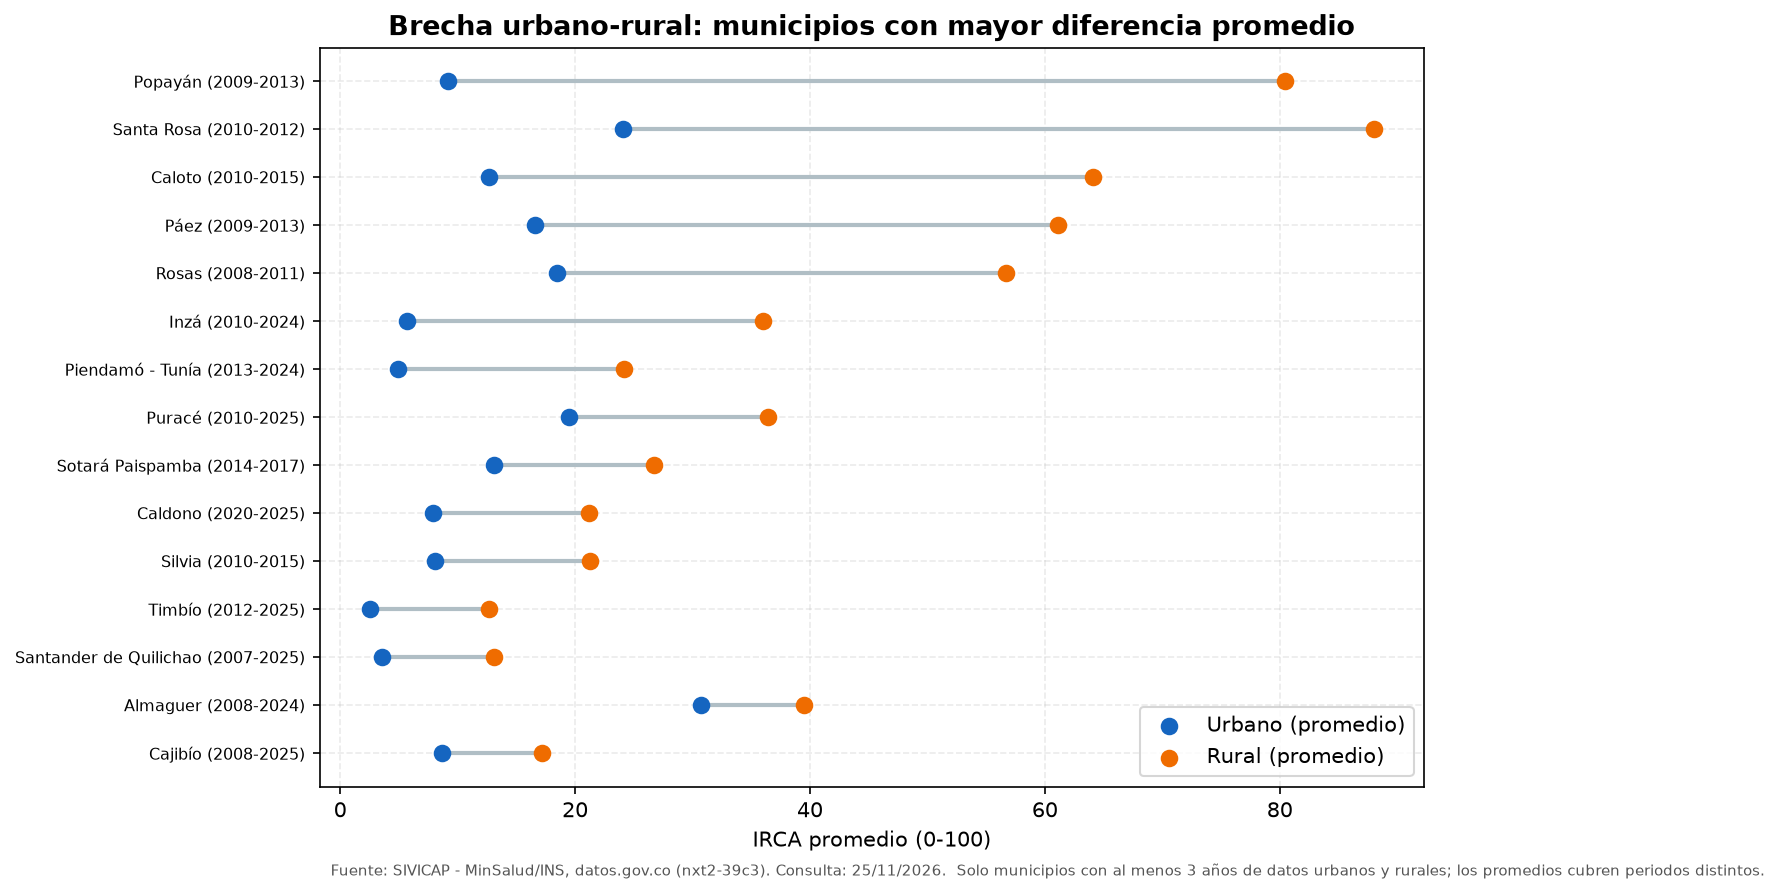

In [11]:
fig_brecha(brecha_municipio)
display(Image(filename="figures/fig_04_urbano_rural.png", width=820))

## 5. Contexto nacional 2025

El Cauca ocupa el puesto 19 de 33 departamentos (1 = menor IRCA). Su IRCA de 7,3 está 0,3 puntos por encima de la mediana departamental (7,0). La mediana municipal nacional es 5,7 y la del Cauca es 6,1 (percentil 51,6).

In [12]:
from src.analysis import contexto_nacional, fig_contexto

contexto, contexto_resumen = contexto_nacional(nac_dep, nac_mun, dep)
contexto_resumen

,indicador,valor,detalle
0,Departamentos con dato 2025,33,Agregados departamentales #TODOS
1,Municipios con dato 2025,1.019,"Base municipal nacional, sin #TODOS"
2,IRCA Cauca 2025,7.3,Agregado departamental oficial
3,Puesto del Cauca,19,1 = menor IRCA (mejor)
4,Mediana departamental 2025,7.0,Mediana de los 33 departamentos
5,IRCA mediano municipal nacional,5.7,1.019 municipios
6,IRCA mediano municipal Cauca,6.1,38 municipios
7,Percentil del municipio mediano del Cauca,51.6,Porcentaje de municipios nacionales con IRCA m...
8,Municipios del Cauca en riesgo medio/alto,4,Corte 2025


In [13]:
contexto[
    contexto["departamento"].isin(
        ["Cauca", "Valle del Cauca", "Huila", "Caquetá", "Putumayo", "Nariño"]
    )
][["departamento", "irca", "nivel_riesgo", "puesto", "diferencia_vs_mediana"]]

,departamento,irca,nivel_riesgo,puesto,diferencia_vs_mediana
18,Huila,4.1,Sin riesgo,7,-2.9
30,Valle del Cauca,4.4,Sin riesgo,9,-2.6
9,Caquetá,6.7,Riesgo bajo,15,-0.3
11,Cauca,7.3,Riesgo bajo,19,0.3
24,Putumayo,17.0,Riesgo medio,30,10.0
22,Nariño,22.5,Riesgo medio,31,15.5


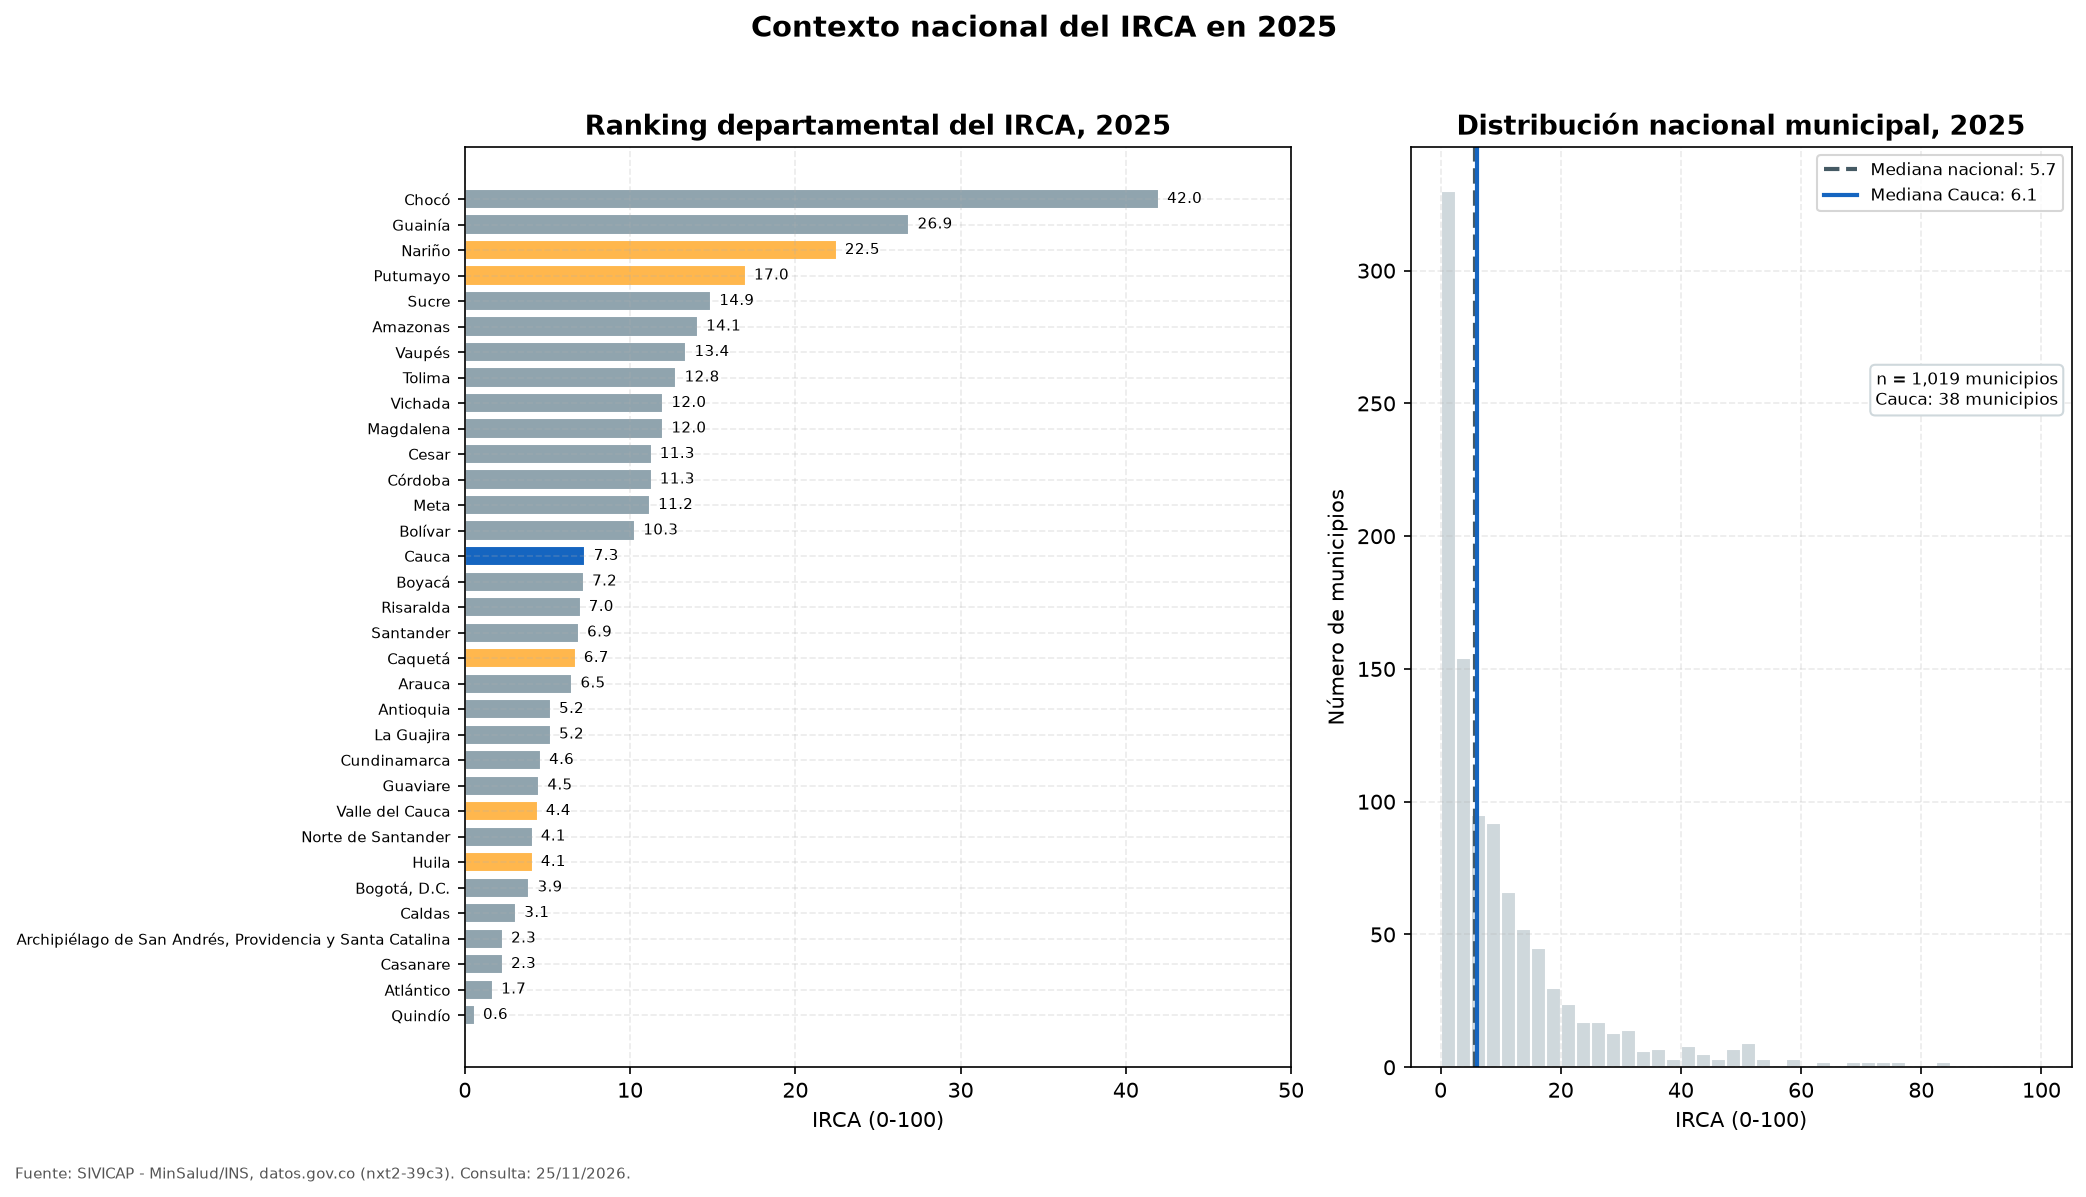

In [14]:
fig_contexto(contexto, nac_mun)
display(Image(filename="figures/fig_06_contexto_nacional.png", width=1000))

## 6. Mapa de calor y trayectorias municipales

El mapa de calor muestra los 42 municipios y los 19 años; el gris indica ausencia de dato. Las trayectorias resaltan los cuatro municipios con mayor IRCA en 2025.

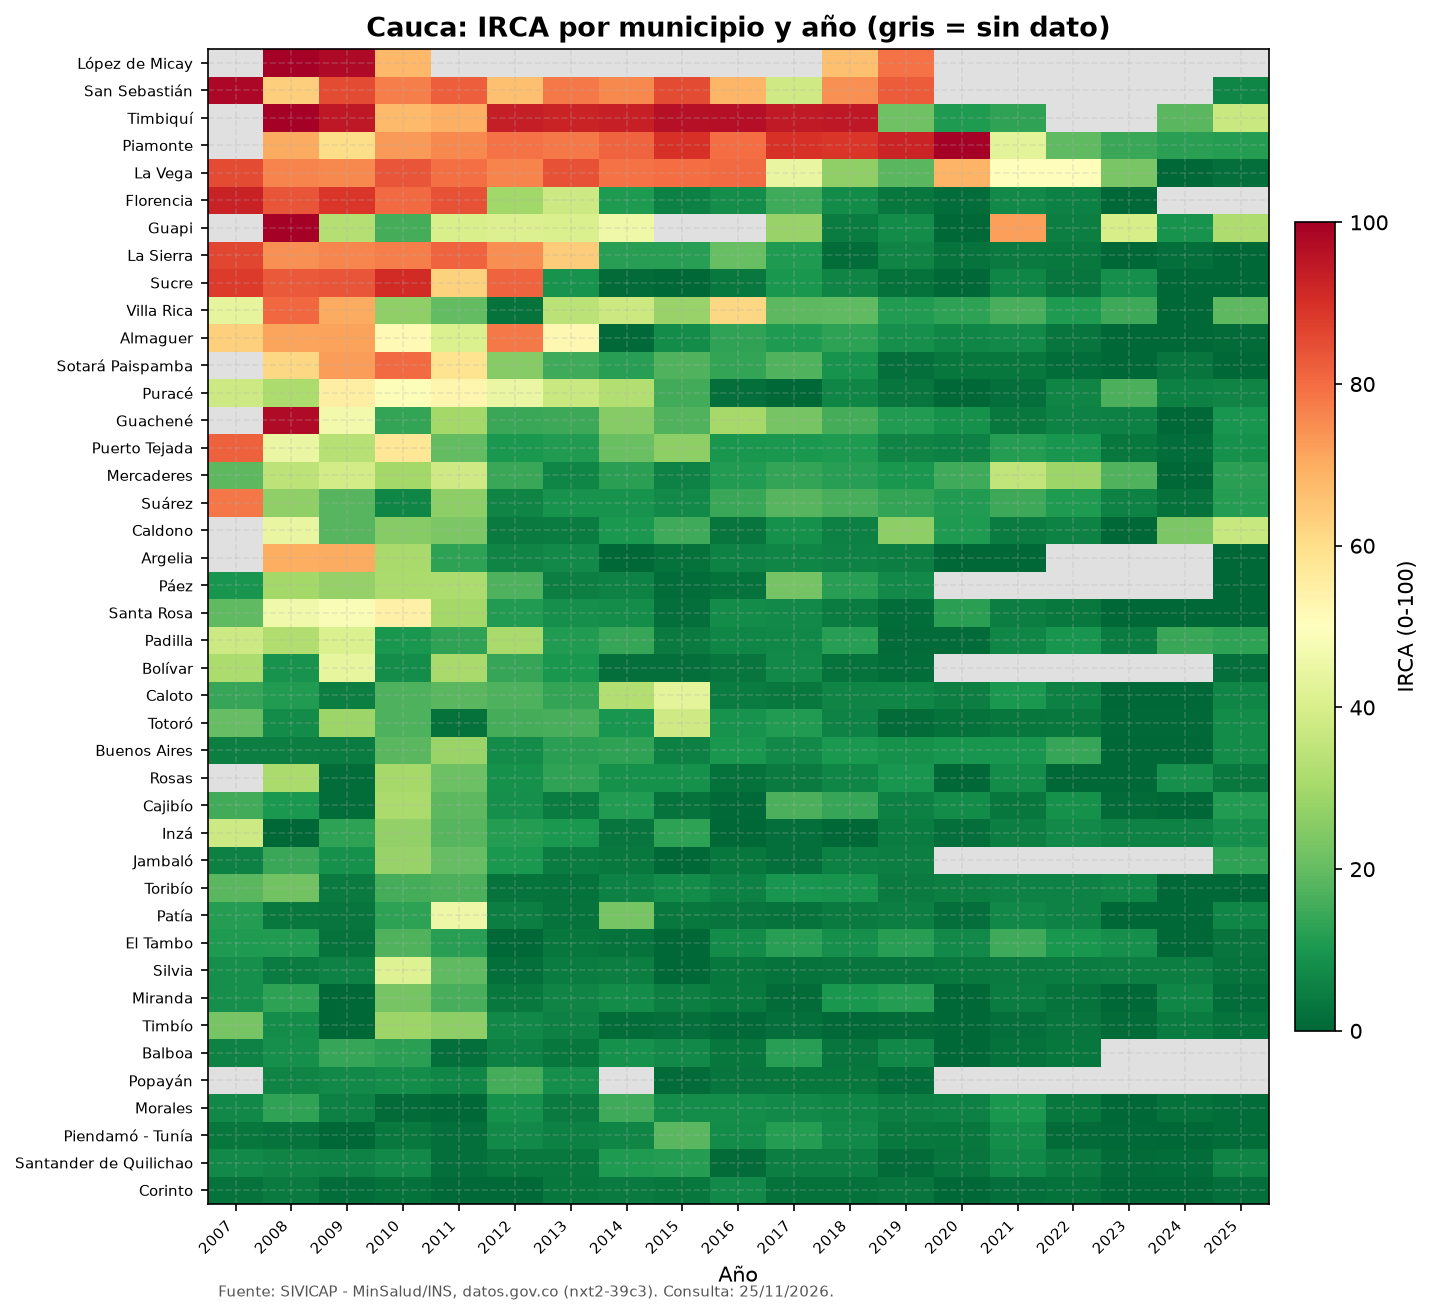

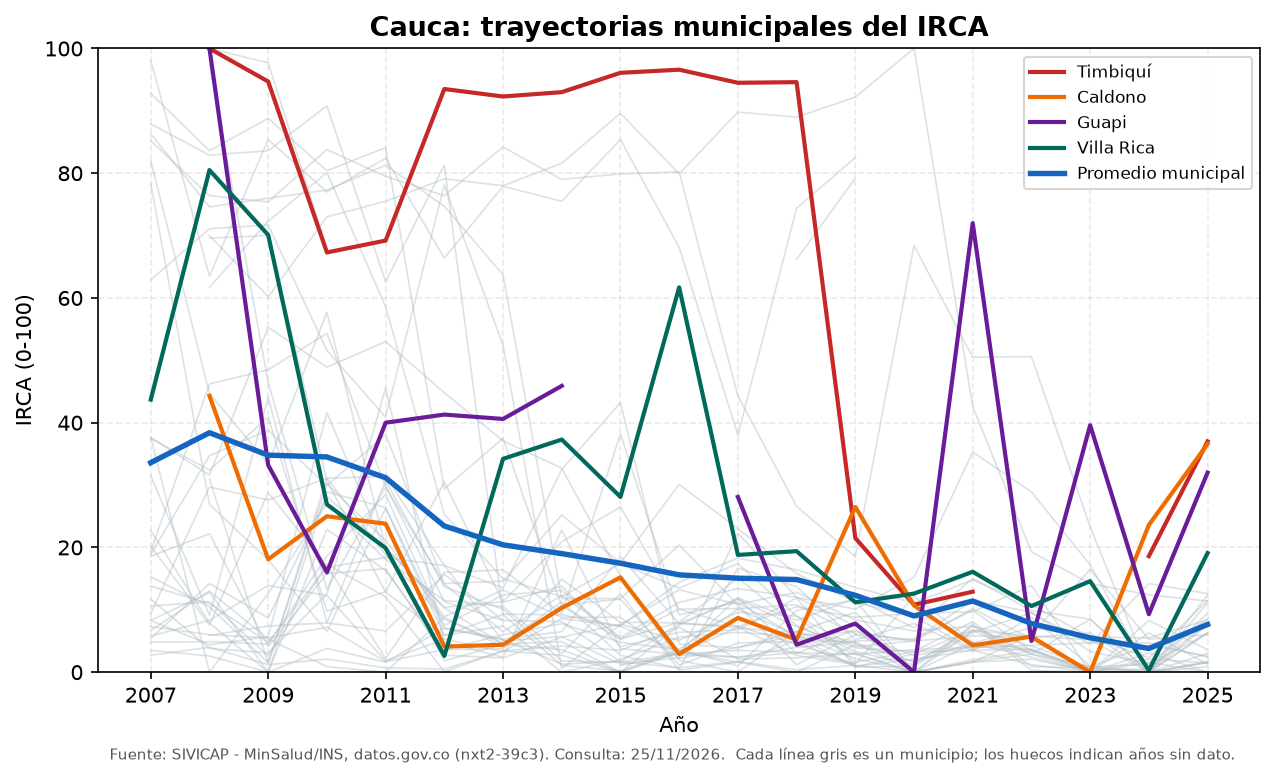

In [15]:
from src.analysis import fig_evolucion_municipal, fig_heatmap

fig_heatmap(cauca)
fig_evolucion_municipal(cauca, ranking)
display(Image(filename="figures/fig_05_heatmap.png", width=820))
display(Image(filename="figures/fig_08_evolucion_municipal.png", width=900))

## 7. Hallazgos para el informe

1. **Mejora con rebote:** 30,7 (2007) → 3,3 (2024) → 7,3 (2025). El aumento de 2025 es de 4,0 puntos y debe monitorearse; los ceros de 2024 y los saltos abruptos sugieren posibles cambios de reporte.
2. **Riesgo concentrado:** 4 de 38 municipios en riesgo medio/alto (10,5%): Timbiquí 37,0, Caldono 36,6, Guapi 32,0 y Villa Rica 19,1. Timbiquí y Caldono son los casos más críticos.
3. **Brecha rural subreportada:** 242 observaciones con ambos datos, brecha promedio 12,2 puntos y mediana 1,9; 66,4% de los registros municipales no tienen IRCA rural. En 2025 solo 8 de 38 municipios tienen dato rural.
4. **Contexto nacional:** Cauca 19/33, cerca de la mediana departamental (7,0) y por encima de la mediana municipal nacional (5,7). Es mejor que Nariño (22,5) y Putumayo (17,0), pero peor que Valle (4,4), Huila (4,1) y Caquetá (6,7).
5. **Datos faltantes:** Popayán solo tiene 2008–2019; en 2025 faltan Balboa, Florencia y López de Micay. Los promedios no representan a los 42 municipios en todos los años.

> **Advertencia:** el IRCA es un indicador agregado del reporte municipal. No identifica hogares, veredas ni causas. Las cifras deben validarse con la autoridad sanitaria y con datos de campo.